# Transicion desde el deposito real: el plan entra por las mudanzas

En el notebook 06 el plan se aplicaba entero al deposito en el momento del corte, de una vez y sin
costo: cada SKU se mudaba a su ubicacion del plan antes de empezar el test. Eso mide lo que da el plan
una vez implementado, pero ningun deposito se reordena entero de un dia para el otro.

Aca se parte del deposito **como esta** al corte y el plan entra solo por las mudanzas que ocurren de
todos modos: cuando un SKU se agota y hay que darle un lugar nuevo, ese lugar lo decide la regla del
slotting. Ademas, los batches se re-arman con la ubicacion que cada SKU tiene en ese momento, que es
lo que veria el sistema de gestion del deposito.

**Pregunta.** Partiendo del deposito real, cuanto se gana, como evoluciona la ganancia semana a semana
y cuanto falta para el techo del notebook 06.

**Contenido.**
0. Configuracion: todos los parametros.
1. Datos y particion.
2. Las mudanzas: el canal por el que entra el plan.
3. Tres regimenes de simulacion: hoy, regla y techo.
4. Re-batching con el deposito del momento.
5. Los planes.
6. Resultados en `medium`.
7. Resultados en `big`.
8. Lectura.

## 0. Configuracion

Lo que cambia respecto del notebook 06 esta marcado con *(nuevo)*.

| componente | parametro | valor | que hace |
|---|---|---|---|
| datos | deposito | `medium`; la seccion 7 repite con `big` | carpeta de `data/v2` |
| particion | fraccion de test | 0,4 *(nuevo; era 0,2)* | el ultimo 40% de los batches es test: 72 dias (unas 10 semanas), para ver la evolucion |
| instancia | demanda $f_i$ y costo $c_l$ | `pick_lines`; distancia caminando al dock | como en el 06 |
| ruteo | recorrido | `s_shape` | S estricto: la caminata depende solo de los pasillos visitados |
| slotting | planes | `demand_greedy`, `aisle_fill`, `merchant_aisle_fill` | calculados con train, como en el 06 |
| estado inicial | deposito al empezar el test | el real al corte *(nuevo; antes, el plan aplicado de una vez)* | seccion 3 |
| reposicion | politica | `plan_aisle` *(nueva)* | si quedan unidades se repone en el lugar; si el SKU se agoto, va a su pasillo del plan (seccion 3) |
| batching | ordenes por batch, ventana, pasadas | 25; 1 (FIFO) y 4; 20 | como en el 06 |
| batching | pasillo de cada SKU | el que tiene en ese momento *(nuevo; antes, el del plan)* | seccion 4 |
| referencia | "hoy" | deposito real, reposicion `random` como en los datos, batches FIFO | todas las diferencias son contra hoy |
| techo | "techo" | plan aplicado de una vez y reposicion `home` | el regimen del notebook 06 |

In [1]:
# Librerias y piezas del paquete.
import gc
import inspect
import time
from types import SimpleNamespace

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from abs_affinity_based_slotting.config import dataset_dir
from abs_affinity_based_slotting.data import WarehouseDataLoader, split_picking_events
from abs_affinity_based_slotting.demand import TopKFilter
from abs_affinity_based_slotting.slotting import build_full_instance, Assignment
from abs_affinity_based_slotting.methods import method_registry
from abs_affinity_based_slotting.simulation import (Simulator, split_replenishments, build_event_stream,
                                                    state_from_initial_stock, state_after_history, reslot_state,
                                                    HomePolicy, RandomStoragePolicy, PlanAislePolicy,
                                                    simulate_rolling, location_aisles)
from abs_affinity_based_slotting.simulation import plan_aisle as modulo_plan_aisle
from abs_affinity_based_slotting.batching import AisleCoverBatching, order_waits

pd.set_option("display.width", 160)

# ---- configuracion (tabla de arriba)
DATASET = "medium"
OTRO = "big"
TEST_SIZE = 0.4
INSTANCIA = dict(demand_metric="pick_lines", affinity_metric="jaccard", cooccurrence_col="order_id",
                 affinity_filter=TopKFilter(k=10), normalize=True, pair_distance_model="aisle")
BATCH_SIZE = 25
VENTANA = 4
MAX_PASSES = 20
SEMILLA = 0
GANADOR = "merchant_aisle_fill"
PLANES = ["demand_greedy", "aisle_fill", "merchant_aisle_fill"]
COLORES = {"demand_greedy": "#2a78d6", "aisle_fill": "#eb6834", "merchant_aisle_fill": "#1baf7a"}

## 1. Datos y particion

Las mismas piezas que en el 06: la particion por la hora de la primera linea de cada batch, la
instancia armada con train, el estado real del deposito al corte despues de reproducir todo train, y
el simulador con recorrido en S. Se agrega el pasillo de cada ubicacion, que usan la regla de
reposicion y el re-batching.

In [2]:
def preparar(nombre):
    # Datos, instancia, estado real al corte, simulador en S y pasillo de cada ubicacion.
    ds = WarehouseDataLoader(dataset_dir("v2", nombre)).load_all()
    split = split_picking_events(ds.picking_events, test_size=TEST_SIZE)
    instance = build_full_instance(split.train, ds.initial_stock, ds.distances, coordinates=ds.coordinates, **INSTANCIA)
    replen_train, replen_test = split_replenishments(ds.replenishment_events, split.train, ds.initial_stock, split.cutoff)
    state0 = state_from_initial_stock(instance, ds.initial_stock)
    state_cut, _ = state_after_history(state0, build_event_stream(split.train, replen_train, instance), instance)
    sim = Simulator.from_tables(instance, ds.coordinates, routing="s_shape")
    inicio = ds.picking_events.groupby("batch_id")["timestamp"].min().sort_values()
    return SimpleNamespace(nombre=nombre, ds=ds, split=split, instance=instance, replen_test=replen_test,
                           state_cut=state_cut, sim=sim, costo=sim.routing.mask_costs(),
                           pasillo_de_ubicacion=location_aisles(sim, instance),
                           minutos_por_batch=float(inicio.diff().dt.total_seconds().median() / 60))


ctx = preparar(DATASET)
inst, test = ctx.instance, ctx.split.test
dias_test = (test["timestamp"].max() - test["timestamp"].min()).total_seconds() / 86400
pd.Series({"pasillos": ctx.sim.routing.n_aisles, "SKUs": inst.n_skus, "ubicaciones": inst.n_locations,
           "batches de train": ctx.split.train["batch_id"].nunique(), "batches de test": test["batch_id"].nunique(),
           "corte entre train y test": ctx.split.cutoff, "dias de test": round(dias_test, 1)}, name=DATASET).to_frame()

,medium
pasillos,8
SKUs,6912
ubicaciones,7680
batches de train,4887
batches de test,3258
corte entre train y test,2026-04-19 14:24:22.733333
dias de test,72.4


## 2. Las mudanzas: el canal por el que entra el plan

En los datos, cuando un pick dejaria el stock de un SKU en negativo, justo antes ocurre una reposicion.
Si al SKU le quedaban unidades, se repone en el mismo lugar. Si se habia agotado, con probabilidad 0,9
se muda a una ubicacion libre elegida al azar. Cada reposicion de los datos trae su origen y su destino,
asi que las mudanzas se cuentan directo: son las reposiciones con destino distinto del origen.

Esas mudanzas son las unicas oportunidades de poner un SKU donde dice el plan sin mover nada de mas.
Cuantas hay en test, y sobre que SKUs caen:

In [3]:
rep = ctx.replen_test
mudanzas = rep[rep["source_location_id"] != rep["target_location_id"]]
lineas_por_sku = test["sku"].value_counts()
mudanzas_por_sku = mudanzas["sku"].value_counts().reindex(lineas_por_sku.index, fill_value=0)
top = lineas_por_sku.rank(ascending=False, method="first") <= 0.1 * len(lineas_por_sku)
pd.Series({"reposiciones en test": len(rep), "mudanzas en test": len(mudanzas),
           "mudanzas por dia": round(len(mudanzas) / dias_test, 1),
           "lineas del 10% de SKUs mas pedidos": f"{lineas_por_sku[top].sum() / lineas_por_sku.sum():.0%}",
           "mudanzas del 10% de SKUs mas pedidos": f"{mudanzas_por_sku[top].sum() / mudanzas_por_sku.sum():.0%}",
           "SKUs que se mudan al menos una vez en test": f"{(mudanzas_por_sku > 0).mean():.0%}",
           "lineas de esos SKUs": f"{lineas_por_sku[mudanzas_por_sku > 0].sum() / lineas_por_sku.sum():.0%}"},
          name=DATASET).to_frame()

,medium
reposiciones en test,31559
mudanzas en test,14268
mudanzas por dia,197.1
lineas del 10% de SKUs mas pedidos,64%
mudanzas del 10% de SKUs mas pedidos,64%
SKUs que se mudan al menos una vez en test,52%
lineas de esos SKUs,86%


La cantidad que se repone casi no depende de cuanto se pide un SKU, asi que los SKUs mas pedidos se
agotan, y se mudan, mucho mas seguido. Por eso el canal de mudanzas apunta justo a los SKUs que mas
pesan en la caminata:

In [4]:
cantidad = rep.groupby("sku")["quantity"].mean()
por_decil = pd.DataFrame({"lineas": lineas_por_sku, "mudanzas": mudanzas_por_sku, "cantidad repuesta": cantidad}).dropna()
por_decil["decil de demanda"] = pd.qcut(por_decil["lineas"].rank(method="first"), 10, labels=range(1, 11))
por_decil.groupby("decil de demanda", observed=True).mean().round(1).T

decil de demanda,1,2,3,4,5,6,7,8,9,10
lineas,4.8,7.1,9.0,11.1,14.0,18.1,24.6,36.7,66.6,319.9
mudanzas,0.5,0.6,0.6,0.8,0.8,1.0,1.3,2.0,3.4,15.9
cantidad repuesta,16.7,20.3,21.6,23.6,25.3,26.8,29.7,30.7,32.9,33.9


En los 72 dias de test hay 14.268 mudanzas, unas 197 por dia. El 10% de SKUs mas pedidos hace el 64% de
las lineas y se lleva el 64% de las mudanzas: su cantidad repuesta es apenas el doble que la del decil
menos pedido (33,9 contra 16,7 unidades), aunque se pide 67 veces mas, asi que se agota y se muda unas
16 veces en el test, contra 0,5 del decil menos pedido. La mitad de los SKUs (52%) se muda al menos una
vez, y esos SKUs hacen el 86% de las lineas. Ese es el alcance del canal: el plan puede llegar rapido a
los SKUs que mas pesan, y a casi nada del resto.

## 3. Tres regimenes de simulacion

Los tres simulan las mismas lineas de picking y las mismas reposiciones de test, con sus momentos y
cantidades de los datos. Cambian el estado del deposito al empezar y a donde va cada reposicion.

| regimen | deposito al empezar | a donde va cada reposicion |
|---|---|---|
| **hoy** | el real al corte | `random`, como en los datos: si quedan unidades, en el lugar; si se agoto, con probabilidad 0,9 a una ubicacion libre al azar |
| **regla** | el real al corte | `plan_aisle`: si quedan unidades, en el lugar; si se agoto, a su pasillo del plan |
| **techo** | el plan aplicado de una vez | `home`: a su ubicacion del plan (el notebook 06) |

**La regla `plan_aisle`.** Cuando un SKU se agota y hay que darle lugar:
1. si alguna de sus ubicaciones ya esta en el pasillo que le da el plan, se queda ahi;
2. si no, va a una ubicacion libre de ese pasillo, la mas cercana a su ubicacion del plan;
3. si ese pasillo no tiene lugar libre, va al pasillo mas cercano que tenga, otra vez a la ubicacion
   libre mas cercana a la del plan.

Apunta al pasillo y no a la ubicacion exacta porque con recorrido en S la caminata depende solo de los
pasillos visitados. Mueve un SKU solo cuando los datos lo mudarian de todos modos (se agoto), asi que
no agrega movimientos: los reemplaza. El codigo:

In [5]:
print(inspect.getsource(modulo_plan_aisle.PlanAislePolicy))

@replenishment_policy_registry.register("plan_aisle")
class PlanAislePolicy:
    """Refill in place or move to where the plan wants the SKU."""

    name = "plan_aisle"

    def __init__(self, location_aisle: np.ndarray, *, trigger: str = "stockout", target: str = "aisle"):
        """
        Parameters
        ----------
        location_aisle:
            Aisle position (0-based, 0 = closest to the dock) of every
            location, e.g. ``routing.bay_aisle[instance.location_bay]``.
        trigger:
            ``stockout`` or ``always`` (see the module docstring).
        target:
            ``aisle`` or ``location``.
        """
        if trigger not in TRIGGERS or target not in TARGETS:
            raise ValueError(f"trigger must be one of {TRIGGERS} and target one of {TARGETS}")
        self.location_aisle = np.asarray(location_aisle, dtype=np.int64)
        self.trigger = trigger
        self.target = target

    def fits(self, loc: int, planned: int) -> bool:
        """Whe

## 4. Re-batching con el deposito del momento

El re-batching es el del notebook 06. Se esperan $25\,W$ ordenes consecutivas (un pool) y se reparten
en $W$ batches de 25 minimizando la caminata total en S del pool,
$$\min_{z} \sum_{k} R_S(M_k), \qquad M_k = \bigcup_{o \,:\, z_{ok} = 1} A(o),$$
con $A(o)$ los pasillos de los SKUs de la orden $o$ y $R_S$ el largo del recorrido en S sobre un conjunto
de pasillos. Se resuelve con la misma heuristica, construir e intercambiar, con un tope de 20 pasadas.

Lo que cambia es de donde sale $A(o)$. En el 06, con el plan aplicado y `home`, cada SKU estaba siempre
en su pasillo del plan, asi que $A(o)$ salia del plan. Aca el pasillo de un SKU cambia con las mudanzas,
asi que $A(o)$ tiene que salir del deposito en el momento de armar el pool. La simulacion avanza
entonces pool por pool (`simulate_rolling`):
1. lee el pasillo actual de cada SKU, el de su ubicacion con mas unidades;
2. re-arma el pool con `AisleCoverBatching` usando esos pasillos;
3. simula sus batches y las reposiciones hasta su ultima linea, y deja el estado para el pool siguiente.

Con $W = 1$ los batches son FIFO y no dependen del estado. En cada paso tambien se registra cuanto
avanzo el plan: la fraccion de la demanda de train cuyos SKUs ya tienen una ubicacion en su pasillo del
plan, y los pasillos por orden con los SKUs donde estan.

In [6]:
def planes_de(c):
    # Los tres planes calculados con train, y el pasillo que cada uno le da a cada SKU.
    i, coords = c.instance, c.ds.coordinates
    planes = {"demand_greedy": method_registry.get("demand_greedy")().solve(i),
              "aisle_fill": method_registry.get("aisle_fill")(coords).solve(i),
              "merchant_aisle_fill": method_registry.get("merchant_aisle_fill")(coords).solve(i)}
    pasillos = {}
    for nombre, plan in planes.items():
        loc = np.array([i.location_index(plan.location_of(k)) for k in i.sku_ids])
        pasillos[nombre] = pd.Series(c.pasillo_de_ubicacion[loc], index=i.sku_ids)
    return planes, pasillos


def correr(c, regimen, plan_nombre, ventana, planes, pasillos):
    # Una corrida. Devuelve una fila de resultados, el registro por batch y el registro por paso.
    t0 = time.time()
    if regimen == "techo":
        # Plan aplicado de una vez: el pasillo de cada SKU es el del plan todo el test.
        plan = planes[plan_nombre]
        batching = AisleCoverBatching(pasillos[plan_nombre], c.costo, batch_size=BATCH_SIZE, window=ventana,
                                      max_passes=MAX_PASSES)
        picking = batching.make_batches(c.split.test)
        res = c.sim.run(reslot_state(c.state_cut, plan, c.instance), build_event_stream(picking, c.replen_test, c.instance),
                        HomePolicy(), planned=plan, seed=SEMILLA)
        log, pasos, mudanzas, faltantes = res.batch_log, None, res.n_relocations, res.shortfall_lines
    else:
        plan = None if regimen == "hoy" else planes[plan_nombre]
        politica = RandomStoragePolicy() if regimen == "hoy" else PlanAislePolicy(c.pasillo_de_ubicacion)
        res = simulate_rolling(c.sim, c.instance, c.state_cut, c.split.test, c.replen_test, politica,
                               aisle_set_cost=c.costo, window=ventana, batch_size=BATCH_SIZE, max_passes=MAX_PASSES,
                               planned=plan, seed=SEMILLA)
        picking, log, pasos = res.picking, res.batch_log, res.step_log
        mudanzas, faltantes = res.n_relocations, res.shortfall_lines
    espera = order_waits(picking, ventana) * c.minutos_por_batch
    fila = {"regimen": regimen, "plan": plan_nombre if regimen != "hoy" else "vigente", "ventana": ventana,
            "caminata media": log["distance"].mean(), "pasillos por batch": log["n_aisles"].mean(),
            "mudanzas": mudanzas, "faltantes": faltantes, "espera media (min)": espera.mean(),
            "segundos": round(time.time() - t0, 1)}
    return fila, log, pasos

**Control.** Con el plan aplicado de una vez y `home`, los SKUs nunca cambian de pasillo, asi que la
simulacion pool por pool tiene que dar exactamente lo mismo que la del 06, que re-arma todo el test de
una vez con los pasillos del plan.

In [7]:
planes, pasillos = planes_de(ctx)
fila_techo, _, _ = correr(ctx, "techo", GANADOR, VENTANA, planes, pasillos)
pool_por_pool = simulate_rolling(ctx.sim, inst, reslot_state(ctx.state_cut, planes[GANADOR], inst), test, ctx.replen_test,
                                 HomePolicy(), aisle_set_cost=ctx.costo, window=VENTANA, planned=planes[GANADOR])
print("techo, todo de una vez:", round(fila_techo["caminata media"], 2),
      "| techo, pool por pool:", round(pool_por_pool.batch_log["distance"].mean(), 2))

techo, todo de una vez: 9428.24 | techo, pool por pool: 9428.24


## 5. Los planes

Los mismos tres planes del notebook 06, calculados con train:

| plan | orden de los SKUs | orden de las ubicaciones |
|---|---|---|
| `demand_greedy` | demanda $f_i$ descendente | distancia al dock ascendente |
| `aisle_fill` | demanda $f_i$ descendente | por pasillo, del mas cercano al dock al mas lejano, y dentro del pasillo por distancia |
| `merchant_aisle_fill` | merchants por demanda total, y dentro de cada merchant por $f_i$ | igual que `aisle_fill` |

El ganador del 06 pone cada merchant en un pasillo; como cada orden es de un solo merchant, cada orden
toca un pasillo. Pasillos por orden de test con cada plan aplicado, y en el deposito real al corte:

In [8]:
lineas = test[["order_id", "sku"]].drop_duplicates()
loc_corte = np.array([ctx.state_cut.primary_location(s) for s in range(inst.n_skus)])
pasillo_al_corte = pd.Series(ctx.pasillo_de_ubicacion[loc_corte], index=inst.sku_ids)
pd.Series({nombre: lineas.assign(a=lineas["sku"].map(sa)).groupby("order_id")["a"].nunique().mean()
           for nombre, sa in {"deposito real al corte": pasillo_al_corte, **pasillos}.items()},
          name="pasillos por orden").round(2).to_frame()

,pasillos por orden
deposito real al corte,2.94
demand_greedy,2.40
aisle_fill,1.94
merchant_aisle_fill,1.03


## 6. Resultados en `medium`

Hoy con FIFO y con ventana 4; la regla con los tres planes; y el techo con `demand_greedy` y el ganador.
Las diferencias son contra hoy con FIFO.

In [9]:
corridas = [("hoy", None, 1), ("hoy", None, VENTANA)]
corridas += [("regla", p, w) for p in PLANES for w in (1, VENTANA)]
corridas += [("techo", p, w) for p in ("demand_greedy", GANADOR) for w in (1, VENTANA)]
filas, logs, pasos = [], {}, {}
for regimen, plan_nombre, w in corridas:
    fila, log, paso = correr(ctx, regimen, plan_nombre, w, planes, pasillos)
    filas.append(fila)
    logs[(regimen, fila["plan"], w)] = log
    pasos[(regimen, fila["plan"], w)] = paso
res = pd.DataFrame(filas)
hoy = res.query("regimen == 'hoy' and ventana == 1")["caminata media"].item()
res["vs hoy (%)"] = (res["caminata media"] / hoy - 1) * 100
print("faltantes:", res["faltantes"].sum(), "| segundos en total:", round(res["segundos"].sum()))

faltantes: 0 | segundos en total: 263


### 6.1 Sobre todo el test

Caminata media por batch en todo el test, y la de los ultimos 14 dias, que muestra hasta donde llega
la regla:

In [10]:
def ultimos_dias(log, dias=14):
    # Caminata media de los batches de los ultimos dias del test.
    return log.loc[log["timestamp"] >= log["timestamp"].max() - pd.Timedelta(days=dias), "distance"].mean()


res["ultimos 14 dias vs hoy (%)"] = [(ultimos_dias(logs[(r.regimen, r.plan, r.ventana)]) / hoy - 1) * 100
                                      for r in res.itertuples()]
tabla = res.set_index(["regimen", "plan", "ventana"])[["caminata media", "vs hoy (%)", "ultimos 14 dias vs hoy (%)",
                                                       "pasillos por batch", "mudanzas", "espera media (min)"]]
tabla.round(1)

caminata media  vs hoy (%)  ultimos 14 dias vs hoy (%)  pasillos por batch  mudanzas  espera media (min)
regimen plan                ventana                                                                                                          
hoy     vigente             1               17824.0         0.0                         0.0                 8.0     13608                16.6
                            4               17098.9        -4.1                        -4.2                 7.3     12570               112.6
regla   demand_greedy       1               17768.2        -0.3                        -0.6                 7.9      4422                16.6
                            4               15389.3       -13.7                       -17.1                 6.4      4398               112.6
        aisle_fill          1               17743.9        -0.4                        -1.0                 7.8      6397                16.6
                            4               15553.5       -12.7                       -16.8                 6.5      6364               112.6
        merchant_aisle_fill 1               17793.4        -0.2                        -0.4                 7.9      3366                16.6
                            4               13991.2       -21.5                       -27.4                 5.8      3362               112.6
techo   demand_greedy       1               17608.7        -1.2                        -1.3                 7.6         0                16.6
                            4               13828.8       -22.4                       -22.4                 5.7         0               112.6
        merchant_aisle_fill 1               17367.8        -2.6                        -3.0                 7.3         0                16.6
                            4                9428.2       -47.1                       -46.3                 3.5         0               112.6

**Hoy** cada batch FIFO visita los 8 pasillos, y re-armar los batches sin cambiar nada mas gana solo
4,1%, porque con el deposito tal como esta las ordenes tocan 2,94 pasillos cada una (seccion 5).

**Con FIFO la regla no gana nada** con ningun plan (entre -0,2% y -0,4%): un batch FIFO mezcla ordenes
de muchos merchants y sigue visitando casi todos los pasillos (7,9 de 8). Es lo mismo que en el 06.

**Con ventana 4 la regla con el ganador gana 21,5% en promedio sobre las 10 semanas del test, y 27,4% en los
ultimos 14 dias.** Con `demand_greedy` la regla gana 13,7% y 17,1%, y con `aisle_fill` 12,7% y 16,8%.
La afinidad sigue pagando en este regimen: el plan por merchant le saca a los otros dos unos 8 puntos
en promedio y unos 10 al final.
En los ultimos 14 dias la regla con el ganador ya supera al techo de `demand_greedy` (-22,4%), que
supone el deposito entero reordenado.

**Falta para el techo.** Con el plan aplicado de una vez el ganador gana 47,1%; la regla llega a 27,4%
al final del test.

**No agrega trabajo.** La regla con el ganador hace 3.362 mudanzas en el test, contra 13.608 de hoy:
mueve un SKU solo si se agoto y no esta en su pasillo, cuando hoy se mueve casi siempre que se agota.
La espera de las ordenes es la misma que en el 06: 17 minutos con FIFO y 113 con ventana 4.

### 6.2 Semana a semana

Diferencia contra hoy de la caminata media de cada semana, con ventana 4. Las semanas de los bordes
estan incompletas.

In [11]:
def por_semana(log):
    return log.groupby(log["timestamp"].dt.to_period("W"))["distance"].mean()


hoy_s = por_semana(logs[("hoy", "vigente", 1)])
semanal = pd.DataFrame({f"{r} {p}": (por_semana(logs[(r, p, VENTANA)]) / hoy_s - 1) * 100
                        for r, p in [("hoy", "vigente"), ("regla", "demand_greedy"), ("regla", "aisle_fill"),
                                     ("regla", GANADOR), ("techo", GANADOR)]})
semanal.insert(0, "batches", logs[("hoy", "vigente", 1)].groupby(logs[("hoy", "vigente", 1)]["timestamp"].dt.to_period("W")).size())
semanal.round(1)

,batches,hoy vigente,regla demand_greedy,regla aisle_fill,regla merchant_aisle_fill,techo merchant_aisle_fill
timestamp,,,,,,
2026-04-13/2026-04-19,18,-3.1,-6.3,-10.3,-4.3,-48.5
2026-04-20/2026-04-26,315,-4.0,-8.2,-8.5,-10.3,-47.0
2026-04-27/2026-05-03,315,-4.1,-10.4,-10.1,-14.6,-47.2
2026-05-04/2026-05-10,315,-4.4,-11.3,-10.3,-18.1,-47.3
2026-05-11/2026-05-17,315,-4.8,-12.1,-11.1,-20.6,-47.4
2026-05-18/2026-05-24,315,-4.0,-13.8,-12.2,-22.0,-48.1
2026-05-25/2026-05-31,315,-3.6,-15.4,-13.3,-24.0,-47.2
2026-06-01/2026-06-07,315,-3.2,-15.7,-13.3,-24.8,-47.2
2026-06-08/2026-06-14,315,-4.4,-15.2,-14.5,-25.7,-47.5


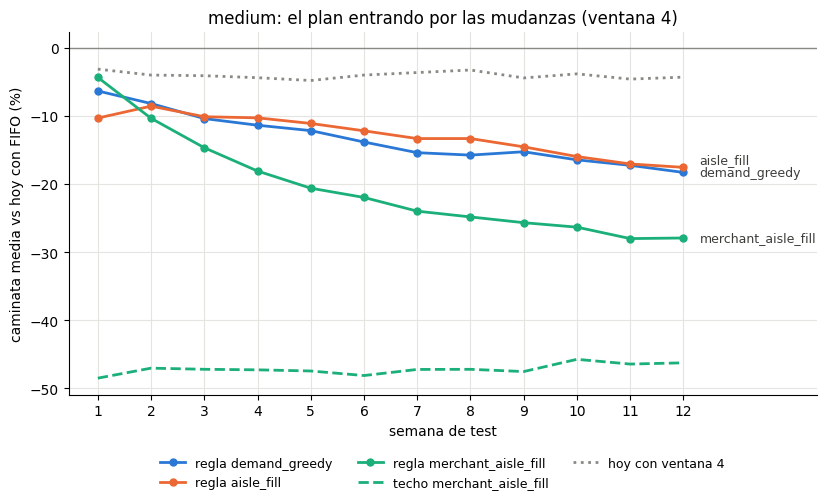

In [12]:
# Diferencia contra hoy por semana, con ventana 4. Linea llena: regla; punteada: techo del ganador.
def etiquetar(ax, x, valores, minimo):
    # Rotulo al final de cada linea, separando los que quedarian a menos de minimo en el eje y.
    nombres = sorted(valores, key=valores.get)
    pos = [valores[nombres[0]]]
    for n in nombres[1:]:
        pos.append(max(valores[n], pos[-1] + minimo))
    for n, yy in zip(nombres, pos):
        ax.annotate(n, (x, valores[n]), xytext=(x + 0.3, yy), textcoords="data", va="center", fontsize=9, color="#3d3d3a")


fig, ax = plt.subplots(figsize=(8.5, 5.2))
x = np.arange(len(semanal))
for p in PLANES:
    ax.plot(x, semanal[f"regla {p}"], marker="o", ms=5, lw=2, color=COLORES[p], label=f"regla {p}")
etiquetar(ax, x[-1], {p: semanal[f"regla {p}"].iloc[-1] for p in PLANES}, 1.8)
ax.plot(x, semanal[f"techo {GANADOR}"], ls="--", lw=2, color=COLORES[GANADOR], label=f"techo {GANADOR}")
ax.plot(x, semanal["hoy vigente"], ls=":", lw=2, color="#8a8a85", label="hoy con ventana 4")
ax.axhline(0, color="#8a8a85", lw=1)
ax.set_xticks(x)
ax.set_xticklabels([str(i + 1) for i in x])
ax.set_xlim(right=x[-1] + 2.5)
ax.grid(True, color="#e5e4e0", lw=0.8)
for lado in ("top", "right"):
    ax.spines[lado].set_visible(False)
ax.set_xlabel("semana de test")
ax.set_ylabel("caminata media vs hoy con FIFO (%)")
ax.set_title(f"{DATASET}: el plan entrando por las mudanzas (ventana {VENTANA})")
ax.legend(frameon=False, loc="upper center", bbox_to_anchor=(0.5, -0.14), ncol=3, fontsize=9)
plt.tight_layout()
plt.show()

### 6.3 Cuanto avanza el plan

Para cada plan, con ventana 4: la fraccion de la demanda de train cuyos SKUs ya tienen una ubicacion en
su pasillo del plan, y los pasillos que toca en promedio una orden con los SKUs donde estan. Es el
promedio de cada semana de los valores que registra cada pool.

In [13]:
avance = {}
for p in PLANES:
    paso = pasos[("regla", p, VENTANA)]
    semana = paso["timestamp"].dt.to_period("W")
    avance[(p, "demanda en su pasillo (%)")] = paso.groupby(semana)["demand_in_plan_aisle"].mean() * 100
    avance[(p, "pasillos por orden")] = paso.groupby(semana)["aisles_per_order"].mean()
avance = pd.DataFrame(avance)
avance.round(2)

demand_greedy                                   aisle_fill                          merchant_aisle_fill                   
                      demanda en su pasillo (%) pasillos por orden demanda en su pasillo (%) pasillos por orden demanda en su pasillo (%) pasillos por orden
timestamp                                                                                                                                                   
2026-04-13/2026-04-19                     16.36               2.89                     15.51               2.90                     14.00               2.89
2026-04-20/2026-04-26                     40.80               2.77                     31.00               2.80                     46.38               2.53
2026-04-27/2026-05-03                     52.85               2.66                     38.32               2.70                     65.40               2.10
2026-05-04/2026-05-10                     58.60               2.61                     41.91               2.65                     72.45               1.91
2026-05-11/2026-05-17                     64.01               2.57                     46.56               2.61                     76.24               1.78
2026-05-18/2026-05-24                     68.11               2.54                     49.97               2.56                     79.41               1.69
2026-05-25/2026-05-31                     70.95               2.51                     52.69               2.54                     81.72               1.62
2026-06-01/2026-06-07                     74.38               2.50                     56.01               2.50                     83.62               1.56
2026-06-08/2026-06-14                     76.55               2.49                     58.67               2.46                     85.07               1.53
2026-06-15/2026-06-21                     78.31               2.47                     60.91               2.44                     86.29               1.48
2026-06-22/2026-06-28                     79.91               2.46                     62.92               2.39                     87.34               1.45
2026-06-29/2026-07-05                     80.65               2.44                     64.13               2.38                     87.86               1.41

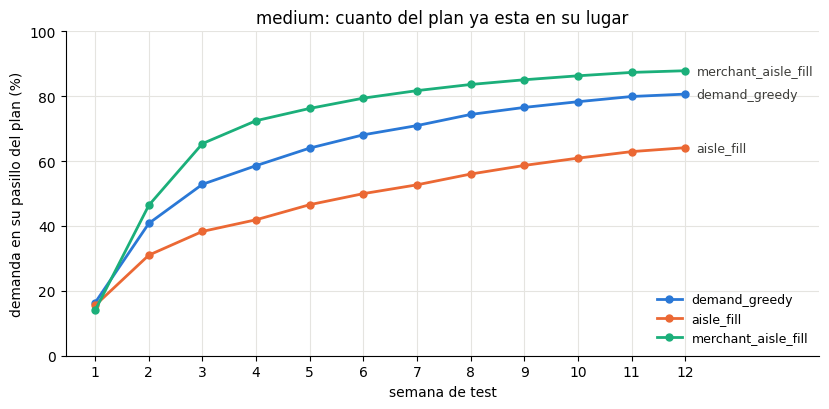

In [14]:
# Fraccion de la demanda en su pasillo del plan, por semana (ventana 4).
fig, ax = plt.subplots(figsize=(8.5, 4.2))
x = np.arange(len(avance))
for p in PLANES:
    y = avance[(p, "demanda en su pasillo (%)")]
    ax.plot(x, y, marker="o", ms=5, lw=2, color=COLORES[p], label=p)
    ax.annotate(p, (x[-1], y.iloc[-1]), xytext=(8, 0), textcoords="offset points", va="center", fontsize=9, color="#3d3d3a")
ax.set_xticks(x)
ax.set_xticklabels([str(i + 1) for i in x])
ax.set_xlim(right=x[-1] + 2.5)
ax.set_ylim(0, 100)
ax.grid(True, color="#e5e4e0", lw=0.8)
for lado in ("top", "right"):
    ax.spines[lado].set_visible(False)
ax.set_xlabel("semana de test")
ax.set_ylabel("demanda en su pasillo del plan (%)")
ax.set_title(f"{DATASET}: cuanto del plan ya esta en su lugar")
ax.legend(frameon=False, loc="lower right", fontsize=9)
plt.tight_layout()
plt.show()

**El plan entra rapido al principio y despues se frena.** Con el ganador, la demanda que ya esta en su
pasillo del plan pasa del 14% al empezar al 46% en la segunda semana, al 65% en la tercera y al 88% en
la ultima. Los pasillos por orden bajan de 2,89 a 1,41, contra 1,03 con el plan completo. El avance por
semana cae de unos 19 puntos (de la segunda a la tercera semana) a menos de 1 al final, porque lo que
queda afuera son SKUs que casi no se agotan (seccion 2).

**Ese resto explica la distancia al techo.** Una orden tiene varios SKUs, y basta con que uno este
fuera de su pasillo para que la orden toque otro pasillo. Por eso el 12% de demanda que falta deja los
pasillos por orden en 1,41, y la caminata en -27,4% en lugar de -47,1%. La caminata sigue bajando al
final del test, alrededor de un punto por semana (6.2), asi que con mas tiempo llegaria algo mas lejos.

**`demand_greedy` llega al 81% y `aisle_fill` al 64%**, y aun con su plan mas avanzado ganan menos,
porque esos planes no ponen las ordenes en un solo pasillo.

## 7. Resultados en `big`

`big` tiene 16 pasillos, 100 merchants y sale un batch cada 14,4 minutos. Se corre hoy con FIFO, la
regla con `demand_greedy` y con el ganador, y el techo del ganador.

In [15]:
del logs, pasos
gc.collect()
cb = preparar(OTRO)
planes_b, pasillos_b = planes_de(cb)
filas_b, logs_b = [], {}
for regimen, plan_nombre, w in [("hoy", None, 1), ("regla", "demand_greedy", VENTANA), ("regla", GANADOR, 1),
                                ("regla", GANADOR, VENTANA), ("techo", GANADOR, 1), ("techo", GANADOR, VENTANA)]:
    fila, log, _ = correr(cb, regimen, plan_nombre, w, planes_b, pasillos_b)
    filas_b.append(fila)
    logs_b[(regimen, fila["plan"], w)] = log
res_b = pd.DataFrame(filas_b)
hoy_b = res_b.query("regimen == 'hoy'")["caminata media"].item()
res_b["vs hoy (%)"] = (res_b["caminata media"] / hoy_b - 1) * 100
res_b["ultimos 14 dias vs hoy (%)"] = [(ultimos_dias(logs_b[(r.regimen, r.plan, r.ventana)]) / hoy_b - 1) * 100
                                        for r in res_b.itertuples()]
res_b.set_index(["regimen", "plan", "ventana"])[["caminata media", "vs hoy (%)", "ultimos 14 dias vs hoy (%)",
                                                 "pasillos por batch", "mudanzas", "faltantes", "espera media (min)"]].round(1)

caminata media  vs hoy (%)  ultimos 14 dias vs hoy (%)  pasillos por batch  mudanzas  faltantes  espera media (min)
regimen plan                ventana                                                                                                                     
hoy     vigente             1               49303.6         0.0                        -0.0                15.9     29860         14                 7.5
regla   demand_greedy       4               35387.3       -28.2                       -32.0                10.8     13540         36                50.7
        merchant_aisle_fill 1               47693.1        -3.3                        -6.0                15.0      9338         14                 7.5
                            4               34123.3       -30.8                       -36.5                10.3      9324         34                50.7
techo   merchant_aisle_fill 1               40167.7       -18.5                       -18.9                12.3         0         14                 7.5
                            4               19780.1       -59.9                       -59.8                 5.3         0         33                50.7

In [16]:
hoy_bs = por_semana(logs_b[("hoy", "vigente", 1)])
pd.DataFrame({f"{r} {p}": (por_semana(logs_b[(r, p, VENTANA)]) / hoy_bs - 1) * 100
              for r, p in [("regla", "demand_greedy"), ("regla", GANADOR), ("techo", GANADOR)]}).round(1)

,regla demand_greedy,regla merchant_aisle_fill,techo merchant_aisle_fill
timestamp,,,
2026-04-13/2026-04-19,-13.2,-13.6,-60.0
2026-04-20/2026-04-26,-20.8,-19.9,-59.8
2026-04-27/2026-05-03,-25.1,-24.8,-60.0
2026-05-04/2026-05-10,-26.0,-27.4,-60.1
2026-05-11/2026-05-17,-27.8,-29.7,-59.7
2026-05-18/2026-05-24,-28.8,-31.3,-60.2
2026-05-25/2026-05-31,-29.2,-32.7,-59.7
2026-06-01/2026-06-07,-30.2,-33.8,-60.0
2026-06-08/2026-06-14,-30.7,-34.9,-59.6


**En `big` el patron se repite.** Hoy cada batch FIFO visita casi los 16 pasillos (15,9). La regla con
el ganador y ventana 4 gana 30,8% en promedio y 36,5% en los ultimos 14 dias, y semana a semana pasa de
-13,6% a -37,5%, todavia bajando. Con `demand_greedy` la regla llega a 32,0% en los ultimos 14 dias:
en `big` la ventaja del plan por merchant es de unos 4,5 puntos al final. El techo del ganador gana
59,9% con ventana 4.

Con FIFO, la regla con el ganador gana 3,3% en promedio y 6,0% al final, y su techo 18,5%: el deposito
vigente de `big` esta tan desordenado que el plan por merchant gana algo incluso sin re-armar los
batches. La espera media con ventana 4 es de 51 minutos. La regla hace 9.324 mudanzas contra 29.860 de
hoy. Hay entre 14 y 36 lineas faltantes por corrida, tambien con hoy.

## 8. Lectura

Todas las cifras son la caminata media por batch en S, contra hoy: el deposito real, con reposiciones
como en los datos y batches FIFO.

**El plan puede entrar sin reordenar el deposito.** Partiendo del deposito real y moviendo un SKU solo
cuando se agota, la regla `plan_aisle` pone en su pasillo del plan el 65% de la demanda en tres semanas
y el 88% en doce (`medium`, 6.3), con menos mudanzas que las que ocurren hoy (6.1). Lo hace porque los
SKUs mas pedidos son los que mas se agotan (2).

**Con re-batching por pasillos, la ganancia crece semana a semana.** Con el plan por merchant y ventana
4, la caminata baja 21,5% en promedio en las 10 semanas de test de `medium` y 27,4% en los ultimos 14 dias; en
`big`, 30,8% y 36,5% (6.1 y 7). Con FIFO la regla no gana casi nada, igual que en el 06.

**La afinidad paga tambien partiendo del deposito real.** Con la misma regla y ventana, el plan por
merchant le gana a `demand_greedy` por unos 10 puntos en `medium` y 4,5 en `big` al final del test.

**El techo del 06 es un techo.** Con el plan aplicado de una vez, el ganador gana 47,1% en `medium` y
59,9% en `big`. La regla llega a algo mas de la mitad de eso en las 10 semanas del test y sigue bajando cerca de un
punto por semana. La distancia la explican los SKUs que casi no se agotan, y que por lo tanto la regla
casi no mueve.

**Lo que este notebook no mide.**
- La espera real de las ordenes (sale de una regla, como en el 06) y la congestion.
- El tiempo de picking: todo se mide en distancia.